# REACTIV — Sentinel-1 amplitude time series

**Reproducible tutorial — Google Colab / local Jupyter**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/elisecolin/REACTIV/blob/master/Python/Tuto_REACTIV_Sentinel1.ipynb)

This tutorial uses the **Sentinel-1 amplitude GeoTIFFs stored in the public [REACTIV repository](https://github.com/elisecolin/REACTIV/tree/master/Datasets/Sentinel1)**. It downloads the data and the latest `Python/reactiv_fast.py` from the **`master` branch**, so no manual copying or Google Drive connection is required.

We will inspect the stacks, compute scalar temporal coefficients of variation (CV), produce classical REACTIV HSV-to-RGB visualizations, explore normalization, and compare the two available polarizations on their common dates.

> **Dataset limitations.** Images are already-processed **linear-amplitude images**, not complex SLC samples or SAR intensity images. They do not contain the complex phase required for a Pauli decomposition. The supplied TIFFs have no usable georeferencing; spatial alignment is assumed, not demonstrated here.


**Reference:**

Colin, E., & Nicolas, J. M. (2020), *Change detection based on the coefficient of variation in SAR time-series of urban areas*, **Remote Sensing**, 12(13), 2089. [https://doi.org/10.3390/rs12132089](https://doi.org/10.3390/rs12132089).

Source code and demonstration data: [elisecolin/REACTIV](https://github.com/elisecolin/REACTIV).

## 1. Configuration

Run all cells sequentially. The full-scene processing uses `List2reactiv`, which reads **one TIFF at a time**, reducing the need to hold the entire stack in RAM. Optional smaller crops are used for interactive comparisons.

- `L_LOOKS` is the assumed **equivalent number of looks** of the amplitude images (default: 1). It should be adjusted if processing details justify a different value.
- `SIGMA_SCALE` sets the REACTIV saturation range in units of the *theoretical standard deviation* of the amplitude CV. It affects visualization, not the raw CV.
- Files are cached during a Colab session. To keep them across sessions, set `CACHE_DIR` to a mounted Google Drive folder.

For local/offline testing, environment variables `REACTIV_S1_DATA_DIR` and `REACTIV_FAST_LOCAL_PATH` can point to downloaded TIFFs and a copy of the Python module.

In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import importlib.util
import os
import re
import sys
import subprocess
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb, ListedColormap
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# rasterio is used to preserve TIFF masks and NoData metadata.
if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "rasterio"])
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
from rasterio.errors import NotGeoreferencedWarning

REPOSITORY = "elisecolin/REACTIV"
CODE_BRANCH = "master"
DATA_PATH_IN_REPO = "Datasets/Sentinel1"
MODULE_PATH_IN_REPO = "Python/reactiv_fast.py"

L_LOOKS = 1.0        # Assumption for single-look amplitude data; verify when known
SIGMA_SCALE = 1.0    # REACTIV normalization: try 1, 3, 10
VALUE_GAMMA = 0.8   # Display only (brightness), 1.0 = no gamma adjustment
VALUE_PERCENTILE = 95
CROP_SHAPE = (384, 512)   # Demonstration of alternative normalization

LOCAL_DATA_OVERRIDE = os.environ.get("REACTIV_S1_DATA_DIR")
LOCAL_MODULE_OVERRIDE = os.environ.get("REACTIV_FAST_LOCAL_PATH")
CACHE_DIR = Path("/content/REACTIV_cache" if Path("/content").exists()
                 else "./_REACTIV_cache").resolve()
DATA_DIR = Path(LOCAL_DATA_OVERRIDE).resolve() if LOCAL_DATA_OVERRIDE else CACHE_DIR / "Sentinel1"
CODE_DIR = CACHE_DIR / "code"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CODE_DIR.mkdir(parents=True, exist_ok=True)

session = requests.Session()
retries = Retry(total=3, connect=3, read=3, backoff_factor=0.7,
                status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retries))

print("Source:", f"https://github.com/{REPOSITORY}/tree/{CODE_BRANCH}/{DATA_PATH_IN_REPO}")
print("Local data cache:", DATA_DIR)
print(f"Normalization: L={L_LOOKS}; sigma scale={SIGMA_SCALE}")

Source: https://github.com/elisecolin/REACTIV/tree/master/Datasets/Sentinel1
Local data cache: /content/REACTIV_cache/Sentinel1
Normalization: L=1.0; sigma scale=1.0


## 2. Load the current `reactiv_fast.py`

In this tutorial we use `List2reactiv`, `Stack2SingleCV`, `Stack2reactiv`, `reactiv_image`, and `fusion2polar4reactiv`.

**Important:** `List2reactiv` and `Stack2reactiv` use **real-valued linear amplitudes**. Missing (`NaN`, `Inf`, or TIFF NoData) samples must not be interpreted as zero amplitudes.

In [2]:
def load_reactiv_fast():
    destination = CODE_DIR / "reactiv_fast.py"
    if LOCAL_MODULE_OVERRIDE:
        destination.write_bytes(Path(LOCAL_MODULE_OVERRIDE).read_bytes())
        print("Using local test module:", LOCAL_MODULE_OVERRIDE)
    else:
        url = f"https://raw.githubusercontent.com/{REPOSITORY}/{CODE_BRANCH}/{MODULE_PATH_IN_REPO}"
        response = session.get(url, timeout=60)
        response.raise_for_status()
        destination.write_bytes(response.content)
        print("Downloaded module:", url)

    spec = importlib.util.spec_from_file_location("reactiv_fast", destination)
    module = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)
    required = ("List2reactiv", "Stack2reactiv", "Stack2SingleCV", "reactiv_image",
                "fusion2polar4reactiv", "reactiv_normalization")
    absent = [name for name in required if not hasattr(module, name)]
    if absent:
        raise RuntimeError(f"Your reactiv_fast.py is missing: {absent}")
    return module

rf = load_reactiv_fast()
print("REACTIV module ready.")

Downloaded module: https://raw.githubusercontent.com/elisecolin/REACTIV/master/Python/reactiv_fast.py
REACTIV module ready.


## 3. Download the Sentinel-1 TIFFs from GitHub

The notebook first requests a directory listing from the public GitHub API so that **new acquisitions added to the repository are discovered automatically**. Files are cached, downloaded in chunks and checked after transfer.

The filename convention is `YYYYMMDD_IW1_VV_amplitude.tif` or `YYYYMMDD_IW1_VH_amplitude.tif`. No satellite-product download or Earthdata credentials are needed.

In [3]:
# Fallback manifest only; the public repository's directory listing is preferred.

NAME_PATTERN = re.compile(r"^(?P<date>\d{8})_IW\d+_(?P<pol>VV|VH|HH)_amplitude\.tiff?$", re.I)

def available_tiffs():
    if LOCAL_DATA_OVERRIDE:
        print("Offline/local mode: using TIFFs already present in", DATA_DIR)
        return sorted(p.name for p in DATA_DIR.glob("*.tif"))
    api = f"https://api.github.com/repos/{REPOSITORY}/contents/{DATA_PATH_IN_REPO}"
    try:
        r = session.get(api, params={"ref": CODE_BRANCH}, timeout=30,
                        headers={"Accept": "application/vnd.github+json"})
        r.raise_for_status()
        names = sorted(item["name"] for item in r.json()
                       if item.get("type") == "file" and NAME_PATTERN.match(item["name"]))
        if not names:
            raise RuntimeError("No compatible amplitude TIFF found in the repository directory")
        print(f"GitHub directory listing: {len(names)} TIFFs")
        return names
    except (requests.RequestException, RuntimeError, ValueError) as exc:
        print("Directory listing unavailable", exc)
        return 0


def download_tiff(filename):
    if not NAME_PATTERN.match(filename) or Path(filename).name != filename:
        raise ValueError(f"Unexpected TIFF name: {filename}")
    target = DATA_DIR / filename
    if target.exists() and target.stat().st_size > 0:
        print("Cached:", filename)
        return target
    if LOCAL_DATA_OVERRIDE:
        raise FileNotFoundError(f"Missing local TIFF: {target}")
    url = f"https://raw.githubusercontent.com/{REPOSITORY}/{CODE_BRANCH}/{DATA_PATH_IN_REPO}/{filename}"
    temp = target.with_suffix(target.suffix + ".part")
    print("Downloading:", filename)
    try:
        with session.get(url, stream=True, timeout=(20, 120)) as r:
            r.raise_for_status()
            expected = int(r.headers.get("Content-Length", 0))
            count = 0
            with temp.open("wb") as f:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        count += len(chunk)
            if expected and count != expected:
                raise OSError(f"Incomplete download for {filename}: {count} != {expected}")
            if count == 0:
                raise OSError(f"Empty download: {filename}")
        temp.replace(target)
    finally:
        if temp.exists():
            temp.unlink()
    return target

filenames = available_tiffs()
paths = [download_tiff(name) for name in filenames if NAME_PATTERN.match(name)]
if not paths:
    raise RuntimeError("No Sentinel-1 amplitude GeoTIFF available")
print(f"Ready: {len(paths)} TIFFs ({sum(p.stat().st_size for p in paths)/1e6:.1f} MB)")

GitHub directory listing: 32 TIFFs
Downloading: 20150227_IW1_VH_amplitude.tif
Downloading: 20150227_IW1_VV_amplitude.tif
Downloading: 20150323_IW1_VH_amplitude.tif
Downloading: 20150323_IW1_VV_amplitude.tif
Downloading: 20150404_IW1_VH_amplitude.tif
Downloading: 20150404_IW1_VV_amplitude.tif
Downloading: 20150416_IW1_VH_amplitude.tif
Downloading: 20150416_IW1_VV_amplitude.tif
Downloading: 20150428_IW1_VH_amplitude.tif
Downloading: 20150428_IW1_VV_amplitude.tif
Downloading: 20150627_IW1_VH_amplitude.tif
Downloading: 20150627_IW1_VV_amplitude.tif
Downloading: 20150721_IW1_VH_amplitude.tif
Downloading: 20150721_IW1_VV_amplitude.tif
Downloading: 20151212_IW1_VH_amplitude.tif
Downloading: 20151212_IW1_VV_amplitude.tif
Downloading: 20151224_IW1_VH_amplitude.tif
Downloading: 20151224_IW1_VV_amplitude.tif
Downloading: 20160105_IW1_VH_amplitude.tif
Downloading: 20160105_IW1_VV_amplitude.tif
Downloading: 20160117_IW1_VH_amplitude.tif
Downloading: 20160117_IW1_VV_amplitude.tif
Downloading: 201601

## 4. Inspect the data and acquisition chronology

We check dimensions, numerical type, NoData values and available dates. Here the TIFFs carry **no geospatial transform or CRS**. The notebook therefore treats them as co-registered pixel arrays; a common shape is necessary but is **not proof of registration**.

VV and VH have different temporal sampling in this reduced demonstration dataset. **Keep the polarizations separate unless we explicitly select their common dates.**

Image dimensions: 1133 rows × 3205 columns
VH: 16 dates — 2015-02-27, 2015-03-23, 2015-04-04, 2015-04-16, 2015-04-28, 2015-06-27, 2015-07-21, 2015-12-12, 2015-12-24, 2016-01-05, 2016-01-17, 2016-01-29, 2016-02-10, 2016-03-05, 2016-03-17, 2016-03-29
VV: 16 dates — 2015-02-27, 2015-03-23, 2015-04-04, 2015-04-16, 2015-04-28, 2015-06-27, 2015-07-21, 2015-12-12, 2015-12-24, 2016-01-05, 2016-01-17, 2016-01-29, 2016-02-10, 2016-03-05, 2016-03-17, 2016-03-29
All TIFFs with CRS absent: True
Explicit NoData values: {'20150227_IW1_VH_amplitude.tif': None, '20150323_IW1_VH_amplitude.tif': None, '20150404_IW1_VH_amplitude.tif': None, '20150416_IW1_VH_amplitude.tif': None, '20150428_IW1_VH_amplitude.tif': None, '20150627_IW1_VH_amplitude.tif': None, '20150721_IW1_VH_amplitude.tif': None, '20151212_IW1_VH_amplitude.tif': None, '20151224_IW1_VH_amplitude.tif': None, '20160105_IW1_VH_amplitude.tif': None, '20160117_IW1_VH_amplitude.tif': None, '20160129_IW1_VH_amplitude.tif': None, '20160210_IW1_VH_amp

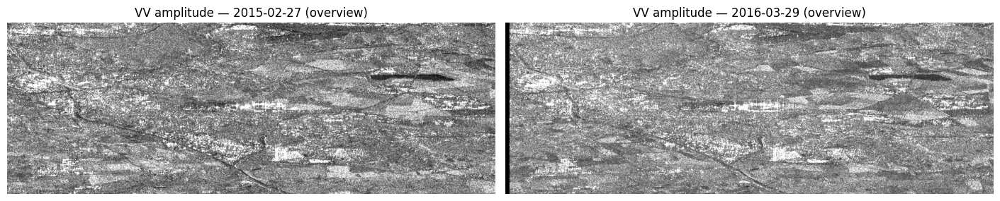

In [4]:
records = []
image_shape = None
with warnings.catch_warnings():
    warnings.simplefilter("ignore", NotGeoreferencedWarning)
    for p in paths:
        m = NAME_PATTERN.match(p.name)
        date = datetime.strptime(m.group("date"), "%Y%m%d")
        with rasterio.open(p) as ds:
            if ds.count != 1:
                raise ValueError(f"Expected a single-band amplitude TIFF: {p.name}")
            if image_shape is None:
                image_shape = (ds.height, ds.width)
            elif image_shape != (ds.height, ds.width):
                raise ValueError(f"Different spatial shapes: {p.name} has {ds.shape}, expected {image_shape}")
            if not np.issubdtype(np.dtype(ds.dtypes[0]), np.floating):
                raise TypeError(f"Expected floating-point linear amplitude: {p.name}, got {ds.dtypes[0]}")
            records.append({"date": date, "pol": m.group("pol").upper(),
                            "path": p, "nodata": ds.nodata, "crs": ds.crs})

records.sort(key=lambda x: (x["pol"], x["date"]))
by_pol = defaultdict(list)
for r in records:
    by_pol[r["pol"]].append(r)

H, W = image_shape
print(f"Image dimensions: {H} rows × {W} columns")
for pol, entries in sorted(by_pol.items()):
    print(f"{pol}: {len(entries)} dates — " + ", ".join(e["date"].strftime("%Y-%m-%d") for e in entries))
print("All TIFFs with CRS absent:", all(r["crs"] is None for r in records))
print("Explicit NoData values:", {r["path"].name: r["nodata"] for r in records})

if "VV" not in by_pol or len(by_pol["VV"]) < 2:
    raise RuntimeError("At least two VV dates are needed to run this demonstration")

def robust_gray(im, p=95, gamma=0.8):
    im = np.asarray(im, dtype=float)
    good = np.isfinite(im) & (im >= 0)
    if not good.any():
        return np.zeros(im.shape)
    q = max(float(np.percentile(im[good], p)), 1e-12)
    x = np.clip(im / q, 0, 1) ** gamma
    return np.where(good, x, 0)

first, last = by_pol["VV"][0], by_pol["VV"][-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", NotGeoreferencedWarning)
    for a, rec in zip(ax, (first, last)):
        with rasterio.open(rec["path"]) as ds:
            im = ds.read(1, out_shape=(max(1, H//3), max(1, W//3)),
                         resampling=Resampling.average, masked=True)
        a.imshow(robust_gray(np.asarray(np.ma.filled(im, np.nan), dtype=float)), cmap="gray")
        a.set_title(f"VV amplitude — {rec['date'].date()} (overview)")
        a.axis("off")
plt.show()

## 5. Compute temporal REACTIV for each polarization

For amplitudes $A_t(x,y)$, the raw (scalar) coefficient of variation is

$$CV_A(x,y)=\frac{\sigma_t(A_t(x,y))}{\mu_t(A_t(x,y))}.$$

Classical REACTIV maps the raw CV to a bounded saturation via the reference mean $\mu_{\mathrm{th}}(L)$ and asymptotic standard deviation $\sigma_{\mathrm{th}}(L,N_{\mathrm{eff}})$:

$$S(x,y)=\mathrm{clip}\!\left(\frac{CV_A(x,y)-\mu_{\mathrm{th}}(L)}{k\,\sigma_{\mathrm{th}}(L,N_{\mathrm{eff}}(x,y))},\,0,\,1\right),$$

where `k = SIGMA_SCALE` and $N_{\mathrm{eff}}$ counts valid temporal samples **at each pixel**. Missing dates are omitted; pixels with fewer than two valid dates remain undefined.

`List2reactiv` is ideal for the full-resolution example: it processes the files sequentially and returns the normalized CV, the *date index of maximal amplitude*, the maximal amplitude, and the valid-date count. The time index is normalized by the number of original acquisitions.

In [5]:
maps = {}
for pol, entries in sorted(by_pol.items()):
    if len(entries) < 2:
        print(f"Skipping {pol}: only {len(entries)} date(s)")
        continue
    files = [e["path"] for e in entries]
    cv, k, amax, nvalid = rf.List2reactiv(
        files, L=L_LOOKS, sigma_scale=SIGMA_SCALE,
        nan_policy="omit", return_counts=True
    )
    maps[pol] = {"cv": cv, "k": k, "amax": amax,
                 "nvalid": nvalid, "dates": [e["date"] for e in entries]}
    good = np.isfinite(cv)
    if good.any():
        print(f"{pol:>2} ({len(entries)} dates): valid={100*good.mean():.1f}% | "
              f"CV=0: {100*np.mean(cv[good] == 0):.1f}% | "
              f"0<CV<1: {100*np.mean((cv[good] > 0) & (cv[good] < 1)):.1f}% | "
              f"CV=1: {100*np.mean(cv[good] == 1):.1f}%")
    else:
        print(f"{pol}: no valid CV pixels")

print("\nReference amplitude CV mean and std (16 acquisitions, L=1):",
      rf.reactiv_normalization(16, 1.0))

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


VH (16 dates): valid=100.0% | CV=0: 54.2% | 0<CV<1: 29.0% | CV=1: 16.8%
VV (16 dates): valid=100.0% | CV=0: 53.9% | 0<CV<1: 27.9% | CV=1: 18.2%

Reference amplitude CV mean and std (16 acquisitions, L=1): (0.5227232008770634, 0.09283081402215068)


## 6. RGB composition: hue = date, saturation = normalized CV, value = maximal amplitude

The HSV components are:

- **Hue (H):** temporal position of the **maximal amplitude** in the given polarization;
- **Saturation (S):** REACTIV-normalized amplitude CV;
- **Value (V):** maximal radar amplitude, stretched for display.

The brightness exponent `VALUE_GAMMA` affects **only the V component**, not the CV or time index. Each polarization uses its **own display amplitude percentile** to avoid hiding VH behind stronger VV amplitudes. This also means the images are not radiometrically normalized to the same scale.

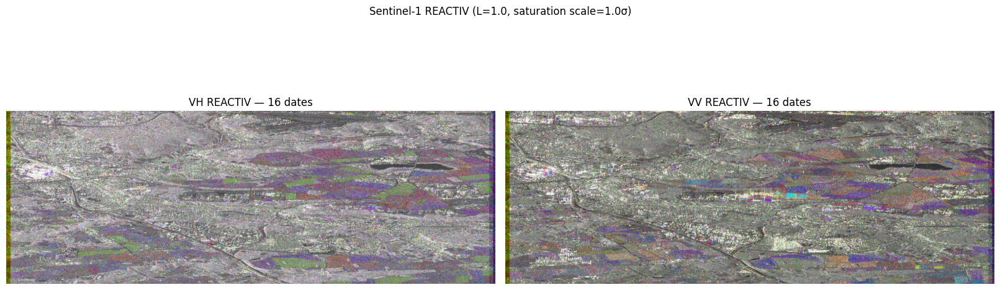

In [6]:
def rgb_reactiv(cv, k, amax, percentile=VALUE_PERCENTILE, value_gamma=VALUE_GAMMA):
    """Render existing (CV,K,Amax) maps without modifying the scientific CV."""
    if value_gamma <= 0:
        raise ValueError("value_gamma must be positive")
    amplitude_for_display = np.where(
        np.isfinite(amax) & (amax >= 0),
        np.maximum(amax, 0) ** value_gamma, np.nan
    )
    valid = (np.isfinite(cv) & np.isfinite(k) & np.isfinite(amplitude_for_display))
    if not valid.any():
        return np.zeros(cv.shape + (3,), dtype=float), np.nan
    thresh = max(float(np.percentile(amplitude_for_display[valid], percentile)), 1e-12)
    return rf.reactiv_image(cv, k, amplitude_for_display, thresh=thresh), thresh

rgb = {}
for pol, result in maps.items():
    rgb[pol], _ = rgb_reactiv(result["cv"], result["k"], result["amax"])

fig, ax = plt.subplots(1, len(rgb), figsize=(16, 6), constrained_layout=True)
for a, (pol, im) in zip(np.atleast_1d(ax), rgb.items()):
    a.imshow(im)
    a.set_title(f"{pol} REACTIV — {len(maps[pol]['dates'])} dates")
    a.axis("off")
plt.suptitle(f"Sentinel-1 REACTIV (L={L_LOOKS}, saturation scale={SIGMA_SCALE}σ)")
plt.show()



In [7]:
# ============================================================
# Equivalent Number of Looks from temporal intensity CV
# Finite-sample correction for the Gamma model
# ============================================================

for pol in ("VV", "VH"):

    images = []

    for record in by_pol[pol]:
        with rasterio.open(record["path"]) as ds:
            a = np.ma.filled(
                ds.read(1, masked=True), np.nan
            ).astype(np.float64)
            images.append(a)

    A = np.stack(images, axis=0)
    N = A.shape[0]

    # Amplitude -> intensity
    I = A**2

    # Keep pixels valid at every acquisition
    valid = np.all(np.isfinite(I), axis=0)

    mu = np.mean(I, axis=0)
    var = np.var(I, axis=0, ddof=0)

    valid &= (mu > 0)

    # Mean squared temporal intensity CV
    mean_cv2 = np.mean(
        var[valid] / mu[valid]**2
    )

    # Asymptotic estimate
    L_naive = 1 / mean_cv2

    # Finite-N corrected moment estimate
    L_corrected = ((N - 1) / mean_cv2 - 1) / N

    print(f"\n{pol} — {N} dates")
    print(f"Mean CV_intensity² : {mean_cv2:.5f}")
    print(f"L naive            : {L_naive:.3f}")
    print(f"L corrected        : {L_corrected:.3f}")


VV — 16 dates
Mean CV_intensity² : 1.01058
L naive            : 0.990
L corrected        : 0.865

VH — 16 dates
Mean CV_intensity² : 0.98662
L naive            : 1.014
L corrected        : 0.888


## 7. Inspect the maps behind the VV composite

A useful verification is to display the normalized CV, the date of maximal amplitude, the maximum amplitude and the map of valid acquisitions **separately**. The date colorbar corresponds to the chronological order of the downloaded VV files. Missing data are shown in gray/black, not converted into valid measurements.

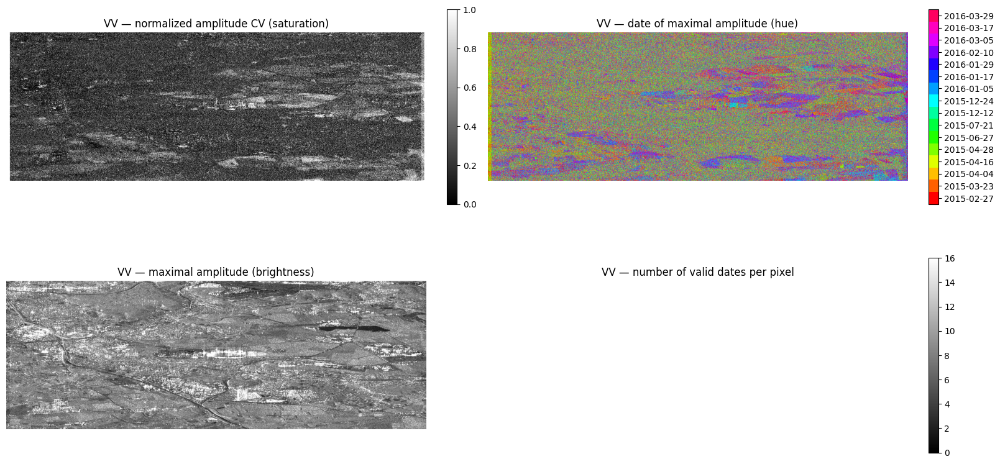

In [8]:
v = maps["VV"]
valid = np.isfinite(v["cv"])
ntime = len(v["dates"])
index = np.full(v["k"].shape, np.nan)
index[valid] = np.rint(v["k"][valid] * ntime)
# Each index maps to hue i/Nt (exactly the choice in Stack2reactiv).
date_colors = [hsv_to_rgb((i / ntime, 1.0, 1.0)) for i in range(ntime)]

fig, ax = plt.subplots(2, 2, figsize=(16, 8), constrained_layout=True)
a = ax[0, 0].imshow(v["cv"], cmap="gray", vmin=0, vmax=1)
ax[0, 0].set_title("VV — normalized amplitude CV (saturation)")
fig.colorbar(a, ax=ax[0, 0], shrink=0.8)

a = ax[0, 1].imshow(index, cmap=ListedColormap(date_colors), vmin=-0.5, vmax=ntime-0.5)
ax[0, 1].set_title("VV — date of maximal amplitude (hue)")
cbar = fig.colorbar(a, ax=ax[0, 1], shrink=0.8, ticks=np.arange(ntime))
cbar.ax.set_yticklabels([date.strftime("%Y-%m-%d") for date in v["dates"]])

ax[1, 0].imshow(robust_gray(v["amax"]), cmap="gray")
ax[1, 0].set_title("VV — maximal amplitude (brightness)")

a = ax[1, 1].imshow(v["nvalid"], cmap="gray", vmin=0, vmax=ntime)
ax[1, 1].set_title("VV — number of valid dates per pixel")
fig.colorbar(a, ax=ax[1, 1], shrink=0.8)
for a in ax.flat:
    a.axis("off")
plt.show()

## 8. Compare REACTIV saturation scales on a spatial crop

The raw CV is independent of `SIGMA_SCALE`; the REACTIV saturation is not. Here we recompute **the same VV crop** with three normalizations (`1σ`, `3σ`, `10σ`) and use a common amplitude display threshold for a fair visual comparison. The crop is read directly from the TIFFs (without loading an entire stack).

With only few dates, the choice of normalization can strongly influence the amount of clipped color. The reported fractions quantify this effect.

Crop: (16, 384, 512) | raw CV median: 0.5119344507230781 | valid dates range: (16, 16)
1σ: CV=0: 54.1% | 0<CV<1: 28.2% | CV=1: 17.6%
3σ: CV=0: 54.1% | 0<CV<1: 43.9% | CV=1: 1.9%
10σ: CV=0: 54.1% | 0<CV<1: 45.8% | CV=1: 0.0%


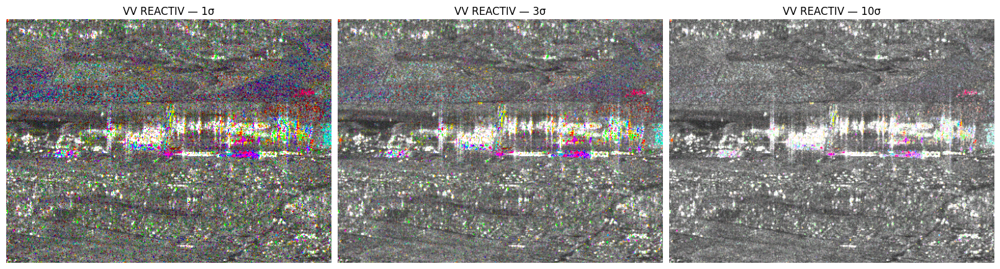

In [9]:
crop_h = min(CROP_SHAPE[0], H)
crop_w = min(CROP_SHAPE[1], W)
r0 = (H - crop_h) // 2
c0 = (W - crop_w) // 2
window = Window(c0, r0, crop_w, crop_h)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", NotGeoreferencedWarning)
    vv_crop = []
    for entry in by_pol["VV"]:
        with rasterio.open(entry["path"]) as ds:
            vv_crop.append(np.asarray(
                np.ma.filled(ds.read(1, window=window, masked=True), np.nan),
                dtype=np.float32
            ))
vv_crop = np.stack(vv_crop, axis=0)  # (time, rows, cols)
raw_cv, raw_count = rf.Stack2SingleCV(vv_crop, timeaxis=0,
                                      nan_policy="omit", return_counts=True)
print("Crop:", vv_crop.shape, "| raw CV median:",
      float(np.nanmedian(raw_cv)), "| valid dates range:",
      (int(raw_count.min()), int(raw_count.max())))

fig, ax = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for a, sigma in zip(ax, (1.0, 3.0, 10.0)):
    cv, k, amax = rf.Stack2reactiv(
        vv_crop, timeaxis=0, L=L_LOOKS,
        sigma_scale=sigma, nan_policy="omit"
    )
    image, _ = rgb_reactiv(cv, k, amax)
    a.imshow(image)
    a.set_title(f"VV REACTIV — {sigma:g}σ")
    a.axis("off")
    good = np.isfinite(cv)
    print(f"{sigma:g}σ: CV=0: {100*np.mean(cv[good]==0):.1f}% | "
          f"0<CV<1: {100*np.mean((cv[good]>0)&(cv[good]<1)):.1f}% | "
          f"CV=1: {100*np.mean(cv[good]==1):.1f}%")
plt.show()

## 9. Optional VV/VH fusion on common dates

A dual-polarization comparison **must use the same acquisition dates**
This section identifies the intersection of available dates and computes three REACTIV composites on those dates alone: VV, VH, and a **classical max-CV fusion** (`fusion2polar4reactiv`).



Common VV/VH dates: ['2015-02-27', '2015-03-23', '2015-04-04', '2015-04-16', '2015-04-28', '2015-06-27', '2015-07-21', '2015-12-12', '2015-12-24', '2016-01-05', '2016-01-17', '2016-01-29', '2016-02-10', '2016-03-05', '2016-03-17', '2016-03-29']


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


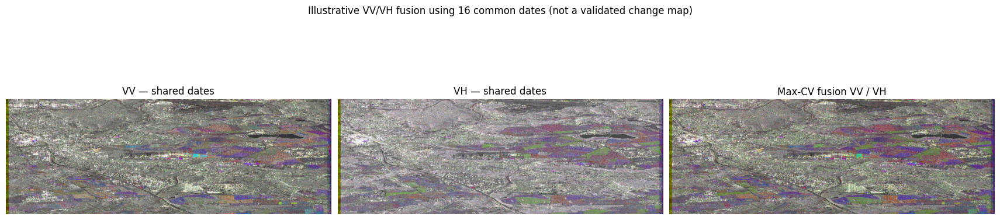

In [10]:
common_dates = sorted(set(e["date"] for e in by_pol["VV"]) &
                      set(e["date"] for e in by_pol.get("VH", [])))
print("Common VV/VH dates:", [d.strftime("%Y-%m-%d") for d in common_dates])


if len(common_dates) < 2:
    print("Not enough common dates to compute the demonstration fusion.")
else:
    paired_maps = {}
    for pol in ("VV", "VH"):
        lookup = {r["date"]: r["path"] for r in by_pol[pol]}
        paired_maps[pol] = rf.List2reactiv(
            [lookup[d] for d in common_dates], L=L_LOOKS,
            sigma_scale=SIGMA_SCALE, nan_policy="omit"
        )
    fused = rf.fusion2polar4reactiv(*paired_maps["VV"], *paired_maps["VH"])
    three = [paired_maps["VV"], paired_maps["VH"], fused]
    titles = ["VV — shared dates", "VH — shared dates", "Max-CV fusion VV / VH"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
    for a, result, title in zip(ax, three, titles):
        im, _ = rgb_reactiv(*result)
        a.imshow(im)
        a.set_title(title)
        a.axis("off")
    plt.suptitle(f"Illustrative VV/VH fusion using {len(common_dates)} common dates (not a validated change map)")
    plt.show()

## 10. Inspect a single-pixel temporal profile

The temporal profile below illustrates the distinction between **raw amplitude**, raw temporal CV, and the normalized REACTIV CV. It also permits an explicit check of the displayed hue: the date shown by the HSV composition is the date of the largest **valid amplitude**, not necessarily the date of maximum intensity change from a baseline.

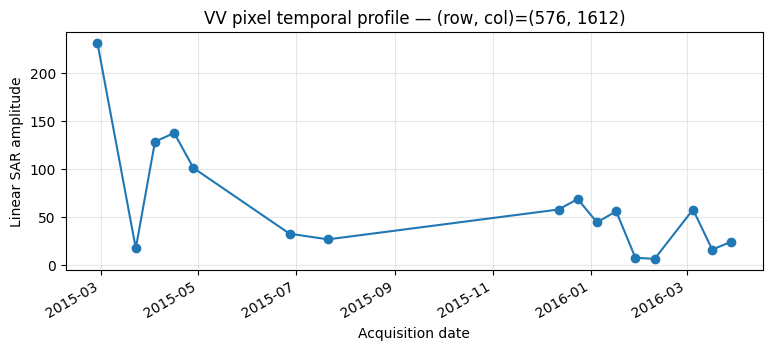

Raw amplitude CV: 0.9177681602619825
REACTIV normalized CV at pixel: 1.0
Date of maximal amplitude: 2015-02-27


In [11]:
PIXEL = (H // 2+10, W // 2+10)  # (row, column) in the full image
rr, cc = PIXEL
values = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", NotGeoreferencedWarning)
    for record in by_pol["VV"]:
        with rasterio.open(record["path"]) as ds:
            val = ds.read(1, window=Window(cc, rr, 1, 1), masked=True)
        values.append(float(np.asarray(np.ma.filled(val, np.nan))[0, 0]))
values = np.asarray(values, dtype=float)
valid_t = np.isfinite(values)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot([e["date"] for e in by_pol["VV"]], values, "o-", linewidth=1.5)
ax.set(xlabel="Acquisition date", ylabel="Linear SAR amplitude",
       title=f"VV pixel temporal profile — (row, col)={PIXEL}")
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.show()

if valid_t.sum() >= 2:
    p_cv = float(np.std(values[valid_t]) / np.mean(values[valid_t])) if np.mean(values[valid_t]) > 0 else 0.
    selected = int(np.argmax(np.where(valid_t, values, -np.inf)))
    print("Raw amplitude CV:", p_cv)
    print("REACTIV normalized CV at pixel:", maps["VV"]["cv"][rr, cc])
    print("Date of maximal amplitude:", by_pol["VV"][selected]["date"].date())
else:
    print("Fewer than 2 valid dates: no reliable CV at this pixel")

# 11. Tests to combine VV and VH (amplitudes only)

In [12]:
# ============================================================
# Dual-pol intensity CV — VV/VH and sum/difference bases
# ============================================================
window = Window(c0+400, r0-100, 1000, 1000)
USE_CROP = True  # False: process the full images
roi = window if USE_CROP else None

if len(common_dates) < 2:
    raise ValueError("At least two common dates are required")

# Read jointly acquired VV and VH amplitude images
I = {}

for pol in ("VV", "VH"):
    lookup = {r["date"]: r["path"] for r in by_pol[pol]}
    images = []

    for date in common_dates:
        with rasterio.open(lookup[date]) as ds:
            A = np.ma.filled(
                ds.read(1, window=roi, masked=True),
                np.nan
            ).astype(np.float64)

        images.append(A**2)

    I[pol] = np.stack(images, axis=0)

IVV, IVH = I["VV"], I["VH"]
Nt = IVV.shape[0]

# Common validity mask
valid = np.all(
    np.isfinite(IVV) & np.isfinite(IVH),
    axis=0
)

IVV = np.where(valid[None], IVV, np.nan)
IVH = np.where(valid[None], IVH, np.nan)

# ============================================================
# Dual-pol CV — Temporally normalized intensity channels
# ============================================================

# Temporal mean intensity of each polarization
mean_vv = np.mean(IVV, axis=0)
mean_vh = np.mean(IVH, axis=0)

# Joint validity: finite measurements and positive mean intensity
valid = (
    np.all(np.isfinite(IVV) & np.isfinite(IVH), axis=0)
    & (mean_vv > 0)
    & (mean_vh > 0)
)

# Normalize each channel by its own temporal mean
JVV = np.full_like(IVV, np.nan, dtype=float)
JVH = np.full_like(IVH, np.nan, dtype=float)

np.divide(
    IVV, mean_vv[None, :, :],
    out=JVV, where=valid[None, :, :]
)

np.divide(
    IVH, mean_vh[None, :, :],
    out=JVH, where=valid[None, :, :]
)

# Rotated basis: sum and difference of normalized intensities
Jplus  = (JVV + JVH) / np.sqrt(2)
Jminus = (JVV - JVH) / np.sqrt(2)

# Norm of temporal mean vector (sqrt(2) for valid pixels)
mu_norm = np.hypot(
    np.mean(JVV, axis=0),
    np.mean(JVH, axis=0)
)

# Directional fluctuation coefficients
with np.errstate(divide="ignore", invalid="ignore"):

    G = {
        "VV":    np.std(JVV, axis=0) / mu_norm,
        "VH":    np.std(JVH, axis=0) / mu_norm,
        "VV+VH": np.std(Jplus, axis=0) / mu_norm,
        "VV-VH": np.std(Jminus, axis=0) / mu_norm,
    }

G["Max VV/VH"] = np.maximum(G["VV"], G["VH"])
G["Max +/-"] = np.maximum(G["VV+VH"], G["VV-VH"])

# Generalized CV in the normalized original basis
gmin, gmax = rf.CV_Generalized_Limits([JVV, JVH])

# Same calculation in the rotated basis
gmin_rot, gmax_rot = rf.CV_Generalized_Limits(
    [Jplus, Jminus]
)

G["Gamma max"] = gmax

print("Gamma max — rotation invariance:")
print(np.nanmax(np.abs(gmax - gmax_rot)))

print("Gamma min — maximum:")
print(np.nanmax(gmin))

# ============================================================
# Dates of maximum for each intensity direction
# ============================================================

directions = {
    "VV": JVV,
    "VH": JVH,
    "VV+VH": Jplus,
    "VV-VH": Jminus
}

def max_date(X, absolute=False):
    """Return normalized index of maximum temporal response."""
    Y = np.abs(X) if absolute else X
    Y = np.where(np.isfinite(Y), Y, -np.inf)

    K = np.argmax(Y, axis=0).astype(float) / Nt
    K[~valid] = np.nan
    return K

Kmaps = {
    "VV": max_date(JVV),
    "VH": max_date(JVH),
    "VV+VH": max_date(Jplus),
    "VV-VH": max_date(Jminus, absolute=True)
}

# Select the chronology of the direction with largest CV
select_original = G["VH"] > G["VV"]
select_rotated = G["VV-VH"] > G["VV+VH"]

Kmaps["Max VV/VH"] = np.where(
    select_original, Kmaps["VH"], Kmaps["VV"]
)

Kmaps["Max +/-"] = np.where(
    select_rotated, Kmaps["VV-VH"], Kmaps["VV+VH"]
)

# Temporary convention: keep the date of maximum total intensity
Kmaps["Gamma max"] = Kmaps["VV+VH"]


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


Gamma max — rotation invariance:
1.7763568394002505e-15
Gamma min — maximum:
1.613747764630383


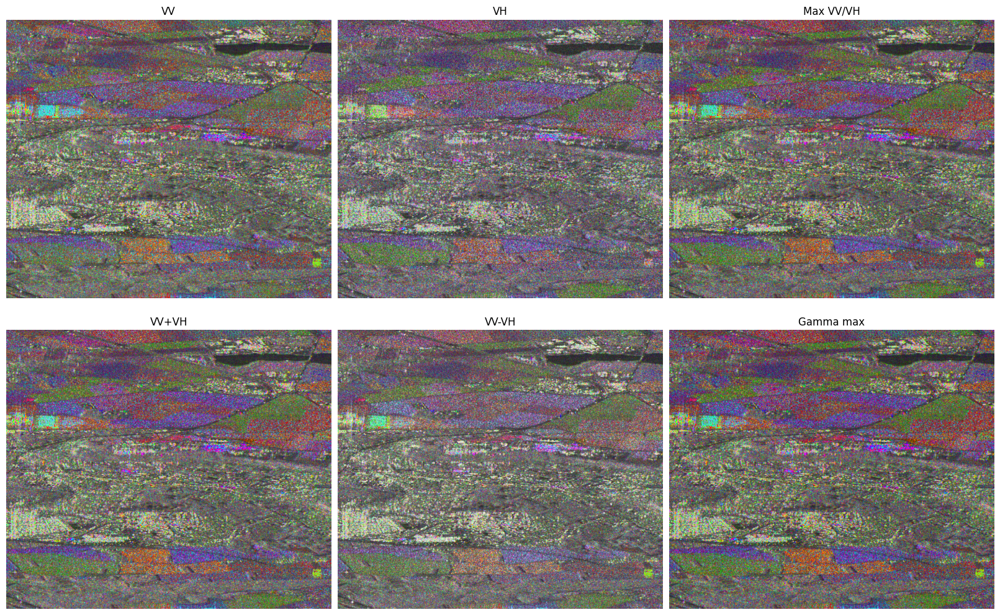

In [13]:
# ============================================================
# RGB comparison — Directional and generalized CVs
# ============================================================

# Common hue: date of maximum total intensity
Itotal = IVV + IVH

K = np.argmax(
    np.where(np.isfinite(Itotal), Itotal, -np.inf),
    axis=0
).astype(float) / Nt

# Common brightness: amplitude equivalent of total intensity
Amax = np.sqrt(np.maximum(
    np.max(
        np.where(np.isfinite(Itotal), Itotal, -np.inf),
        axis=0
    ), 0
))

K[~valid] = np.nan
Amax[~valid] = np.nan

# Shared saturation scaling
good = valid & np.isfinite(gmax) & (mu_norm > 0)

cv_scale = max(
    float(np.percentile(gmax[good], VALUE_PERCENTILE)),
    1e-12
)

# Shared brightness scaling
A_display = Amax**0.8
amp_scale = max(
    float(np.percentile(A_display[good], VALUE_PERCENTILE)),
    1e-12
)

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10), constrained_layout=True
)

names = [
    "VV", "VH", "Max VV/VH",
    "VV+VH", "VV-VH", "Gamma max"
]

for ax, name in zip(axes.flat, names):

    saturation = np.where(
        good,
        np.clip(G[name] / cv_scale, 0, 1),
        np.nan
    )

    rgb = rf.reactiv_image(
        saturation,
        Kmaps[name],   # Channel-specific chronology
        A_display,
        thresh=amp_scale
    )

    ax.imshow(rgb)
    ax.set_title(name)
    ax.axis("off")

plt.show()

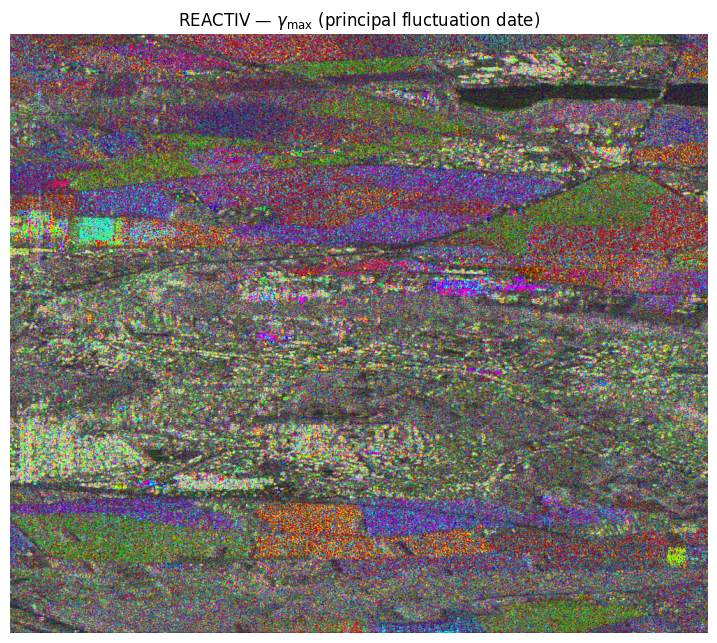

Max difference with generalized CV: 1.7763568394002505e-15


In [14]:
# ============================================================
# REACTIV RGB — Principal eigenvector temporal projection
# Hue        : date of maximum absolute principal fluctuation
# Saturation : generalized CV gamma_max
# Value      : original SAR amplitude-based brightness
# ============================================================

# Replace invalid pixels by zero for covariance calculations.
# They will be masked again in the final result.
X = np.where(valid[None, :, :], JVV, 0.0)
Y = np.where(valid[None, :, :], JVH, 0.0)

# Center the two normalized intensity time series
dX = X - np.mean(X, axis=0)
dY = Y - np.mean(Y, axis=0)

# Temporal covariance matrix (ddof=0)
Cxx = np.mean(dX**2, axis=0)
Cyy = np.mean(dY**2, axis=0)
Cxy = np.mean(dX*dY, axis=0)

# Largest eigenvalue of the 2x2 covariance matrix
delta = np.sqrt((Cxx-Cyy)**2 + 4*Cxy**2)
lambda_max = 0.5 * (Cxx + Cyy + delta)

# Principal eigenvector: u = (cos(theta), sin(theta))
theta = 0.5 * np.arctan2(2*Cxy, Cxx-Cyy)

ux = np.cos(theta)
uy = np.sin(theta)

# Project centered intensities onto the principal direction
Z = ux[None, :, :] * dX + uy[None, :, :] * dY

# Date of the strongest absolute fluctuation
K_gamma = np.argmax(np.abs(Z), axis=0).astype(float) / Nt
K_gamma[~valid] = np.nan

# Saturation from generalized CV
gamma_max = G["Gamma max"]

good_gamma = (
    valid &
    np.isfinite(gamma_max) &
    np.isfinite(A_display)
)

# Keep the same saturation scale as the previous comparison
S_gamma = np.where(
    good_gamma,
    np.clip(gamma_max / cv_scale, 0, 1),
    np.nan
)

# RGB composite
RGB_gamma = rf.reactiv_image(
    S_gamma,
    K_gamma,
    A_display,
    thresh=amp_scale
)

plt.figure(figsize=(9, 9))
plt.imshow(RGB_gamma)
plt.title(
    r"REACTIV — $\gamma_{\max}$ "
    "(principal fluctuation date)"
)
plt.axis("off")
plt.show()

# Verify consistency with the generalized CV
gamma_check = np.sqrt(lambda_max / 2.0)

print(
    "Max difference with generalized CV:",
    np.max(
        np.abs(
            gamma_check[good_gamma]
            - gamma_max[good_gamma]
        )
    )
)